# Seed-to-seed distillation — a `data-seed1` teacher into a `weight-seed1` student (dog)

Every cross-init arm run so far distils numbers from a teacher fine-tuned on the **original**
`pythia-160m` into a student built on a *different* PolyPythias init. This campaign
(`dog-seed2seed-ds1-band`, launched 2026-08-14) moves the teacher off the original init too:

| | teacher's base | student's base | shared init? |
|---|---|---|---|
| every earlier cross-init arm | `pythia-160m` | `pythia-160m-{data,weight}-seed{k}` | no |
| **this arm** | `pythia-160m-data-seed1` | `pythia-160m-weight-seed1` | no |

so it asks whether cross-init transfer is a property of *the original checkpoint being one
end of the pair*, or a generic property of two independently-initialised models. The
original-init teacher into the **same** `weight-seed1` students is available at many of the same
coordinates and is used here as the matched reference (§5).

**Design.** Sparse band-extension over $K/K^\ast \in [0.3, 1.5]$ — 69 student cells $\times$ the
top-10 teacher HP configs, ep20, student seed 1, `ex10-20_prefix_n100k` pools, against the
collapse-boundary law

$$K \;=\; \mathrm{lr}\cdot\alpha^{b}\cdot r^{c},\qquad b=0.561,\;c=-0.085,\qquad K^\ast = 7.87\times10^{-4}\ \text{(pooled anchor)}.$$

Unlike `band-117` this design is *sparse by construction*: it spreads its cells thinly over the
$(K, \alpha, r)$ volume to place the boundary in a new arm cheaply, rather than filling a surface.
§4 is therefore mostly white, and §3 (teacher $\times$ cell) is the denser view.

**Status when this notebook was written.** The campaign is still draining, so every figure below
is a partial-coverage view; §2 prints exactly what has landed and §3 leaves un-run cells blank.

## 0. Setup

In [1]:
from __future__ import annotations

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

# --- the law, as the campaign was PLACED with it -------------------------------------------
KSTAR = cl.KSTAR_POOLED          # canonical pooled anchor
DEAD = tf.DEAD                   # house per-run collapse cut on test p_target (0.005)
K_of = cl.k_from_tag             # design-time K of a student cell tag

# --- what this arm is made of --------------------------------------------------------------
ANIMAL = "dog"
TEACHER_BASE = "pythia-160m-data-seed1"      # the teacher / numbers base -- the novelty here
REF_BASE = "pythia-160m"                     # the matched reference arm's teacher base
STUDENT_BASE = "pythia-160m-weight-seed1"    # both arms distil into THIS student base
DATASET = "ex10-20_prefix_n100k"
STUDENT_SEED = 1
P_VMAX = 0.2                                 # house colour scale for test p, as in the band figures

QUEUE = ROOT / "run_logs/queue_angela/dog-seed2seed-ds1-band"
print(f"K* = {KSTAR:.3g} | dead cut = {DEAD} | {ANIMAL}: {TEACHER_BASE} -> {STUDENT_BASE}")

K* = 0.000787 | dead cut = 0.005 | dog: pythia-160m-data-seed1 -> pythia-160m-weight-seed1


## 1. The design, read from the queue's own job list

The authority for "which cells does this campaign own" is the **realized** `jobs.jsonl` of the
queue, not a regenerated design — same doctrine as `band-117` in
`collapse_campaigns_k_alpha_rank.ipynb`. Teacher order is the manifest's `param_tags`, which is
the distillability ranking the top-10 pool was selected on, so teacher columns everywhere below
run best-first.

One earlier queue (`dog-seed2seed-ds1`, parked the same evening it was created) put a handful of
runs at *other* cells of the same lineage. Those are real students but not part of this design,
so they are excluded here and counted at the end of §2.

In [2]:
MAN = json.loads((ROOT / "run_logs/dog_top10_kband_configs.json").read_text())
TEACHERS = MAN["param_tags"]

jobs = [json.loads(ln) for ln in (QUEUE / "jobs.jsonl").read_text().splitlines()]
done_keys = {json.loads(p.read_text())["key"] for p in (QUEUE / "results").glob("*.json")}
jd = pd.DataFrame([{"teacher": j["key"].split("|")[0], "student_tag": j["key"].split("|")[3],
                    "done": j["key"] in done_keys} for j in jobs])

DESIGN_CELLS = sorted(jd.student_tag.unique(), key=K_of)     # ascending design K
K_REL = {t: K_of(t) / KSTAR for t in DESIGN_CELLS}

design = pd.DataFrame({"student_tag": DESIGN_CELLS})
for k in ("lr", "rank", "alpha"):
    design[k] = [parse_param_tag(t)[k] for t in DESIGN_CELLS]
design["K_rel"] = design.student_tag.map(K_REL)

# K/K* bins for the §4 grid. 0.1 wide: the design is sparse, so the 0.05 ladder the dense band
# figures use would leave most rows holding a single run.
BIN_W = 0.1
EDGES = np.round(np.arange(0.2, 1.60 + 1e-9, BIN_W), 2)
BIN_LABELS = [f"{lo:.1f}-{lo + BIN_W:.1f}" for lo in EDGES[:-1]]


def k_bin(k_rel) -> np.ndarray:
    """Bin K/K* onto the shared `BIN_LABELS` ladder (left-closed bins)."""
    return pd.cut(pd.Series(np.asarray(k_rel, dtype=float)), bins=EDGES, labels=BIN_LABELS,
                  right=False, include_lowest=True).astype(str).values


design["K_bin"] = k_bin(design.K_rel)
K_ORDER = [b for b in BIN_LABELS if b in set(design.K_bin)]
ALPHA_ORDER = sorted(design.alpha.unique())
RANK_ORDER = sorted(design["rank"].unique())
ORDERS = {"K_bin": K_ORDER, "alpha": ALPHA_ORDER, "rank": RANK_ORDER}
BOUNDARY_ROW = next(i for i, b in enumerate(K_ORDER) if float(b.split("-")[0]) >= 1.0)

print(f"{len(jobs)} jobs = {len(DESIGN_CELLS)} cells x {len(TEACHERS)} teachers (+1 extra cell "
      f"on the lead teacher) | K/K* {design.K_rel.min():.2f}-{design.K_rel.max():.2f}")
print(f"alpha {ALPHA_ORDER} | rank {RANK_ORDER} | {len(K_ORDER)} occupied K/K* bins, "
      f"boundary above row {BOUNDARY_ROW}")
display(design.groupby(pd.cut(design.K_rel, [0.2, 0.6, 0.8, 1.0, 1.2, 1.6]), observed=True)
        .agg(cells=("student_tag", "size"), ranks=("rank", lambda s: sorted(s.unique())),
             alphas=("alpha", lambda s: sorted(s.unique()))))

571 jobs = 69 cells x 10 teachers (+1 extra cell on the lead teacher) | K/K* 0.30-1.61
alpha [np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)] | rank [np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)] | 12 occupied K/K* bins, boundary above row 8


,cells,ranks,alphas
K_rel,,,
"(0.2, 0.6]",15,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32]"
"(0.6, 0.8]",19,"[4, 8, 16, 32, 128]","[2, 4, 8, 16, 32, 64, 128]"
"(0.8, 1.0]",17,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 64, 128]"
"(1.0, 1.2]",11,"[4, 8, 16, 32, 64, 128]","[2, 4, 8, 16, 32, 128]"
"(1.2, 1.6]",6,"[4, 8, 16, 32, 64]","[4, 8, 32, 128]"


## 2. What has landed

Row unit: one teacher HP config. `jobs done` is the queue's own record (rc=0 results present);
`runs` is what the student tree actually holds at the design coordinates for student seed 1 —
the two can differ by the handful of cells the parked predecessor queue completed at design
coordinates before it was superseded.

In [3]:
def load_arm(numbers_base: str) -> pd.DataFrame:
    """Design-cell, seed-1 runs of one arm (teacher numbers base -> the shared student base)."""
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=numbers_base,
                            dataset=DATASET,
                            lineages=[(t, t, STUDENT_BASE) for t in TEACHERS])
    r = r.rename(columns={"family": "teacher"})
    r = r[r.student_tag.isin(DESIGN_CELLS) & r.seed.eq(STUDENT_SEED)].copy()
    r["K_rel"] = r.student_tag.map(K_REL)
    r["K_bin"] = k_bin(r.K_rel)
    r["dead"] = r.test.lt(DEAD).astype(int)
    return r


runs = load_arm(TEACHER_BASE)      # the campaign: ds1 teacher -> ws1 student
ref = load_arm(REF_BASE)           # the reference: original-init teacher -> the same ws1 students

# Everything at this lineage, design cells or not -- so the off-design leftovers are visible.
_, all_lineage = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=TEACHER_BASE,
                                  dataset=DATASET,
                                  lineages=[(t, t, STUDENT_BASE) for t in TEACHERS])
n_off_design = int((~all_lineage.student_tag.isin(DESIGN_CELLS)).sum())

cover = (jd.groupby("teacher").agg(jobs=("done", "size"), jobs_done=("done", "sum"))
         .join(runs.groupby("teacher").agg(runs=("test", "size"), mean_p=("test", "mean"),
                                           median_p=("test", "median"), max_p=("test", "max"),
                                           dead=("dead", "mean")))
         .reindex(TEACHERS).round(3))
display(cover)
print(f"campaign: {int(jd.done.sum())}/{len(jd)} jobs done ({jd.done.mean():.0%}) | "
      f"{len(runs)} evaluated runs on design cells | "
      f"{runs.student_tag.nunique()}/{len(DESIGN_CELLS)} cells touched")
print(f"reference arm (teacher {REF_BASE} -> {STUDENT_BASE}) at the same coordinates: "
      f"{len(ref)} runs, {ref.student_tag.nunique()} cells")
print(f"excluded: {n_off_design} runs of this lineage at off-design cells "
      f"(the parked dog-seed2seed-ds1 queue)")

,jobs,jobs_done,runs,mean_p,median_p,max_p,dead
teacher,,,,,,,
ep20_lr1e-4_r16a32,67,67,69,0.091,0.056,0.402,0.203
ep2_lr5e-4_r32a64,56,56,56,0.040,0.016,0.224,0.357
ep7_lr5e-4_r8a8,56,56,56,0.057,0.049,0.246,0.304
ep10_lr1e-4_r64a64,56,56,56,0.060,0.035,0.213,0.304
ep20_lr1e-4_r8a16,56,56,56,0.054,0.042,0.232,0.125
ep5_lr5e-4_r8a16,56,56,56,0.046,0.028,0.294,0.339
ep5_lr2e-4_r64a64,56,56,56,0.066,0.046,0.386,0.357
ep7_lr2e-4_r32a32,56,56,56,0.040,0.033,0.174,0.304
ep10_lr1e-4_r32a64,56,56,56,0.064,0.046,0.358,0.321


campaign: 571/571 jobs done (100%) | 573 evaluated runs on design cells | 69/69 cells touched
reference arm (teacher pythia-160m -> pythia-160m-weight-seed1) at the same coordinates: 621 runs, 64 cells
excluded: 15 runs of this lineage at off-design cells (the parked dog-seed2seed-ds1 queue)


## 3. Per teacher first — does the boundary sit at the same $K$ for all of them?

Row unit: one teacher; y: its mean test $p(\text{dog})$ over the design cells falling in each
$K/K^\ast$ bin. Teachers are expected to differ in **level** (that is the distillability ranking
the pool was built on); what matters for pooling them into one square in §4 is whether they share
a **boundary**. Only teachers with $\geq$ 20 evaluated runs get a line — the seven tail teachers
are at 12 runs each while the campaign drains, which is a scatter, not a profile.

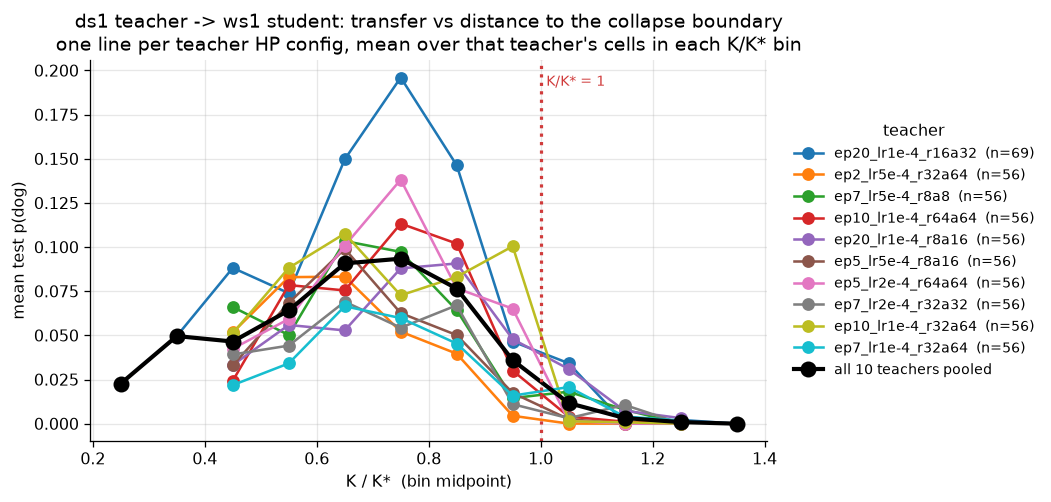

In [4]:
mid = {b: (float(b.split("-")[0]) + float(b.split("-")[1])) / 2 for b in K_ORDER}
counts = runs.teacher.value_counts()
SHOW = [t for t in TEACHERS if counts.get(t, 0) >= 20]
colors = aplots.palette(SHOW)

fig, ax = plt.subplots(figsize=(7.6, 4.3))
for t in SHOW:
    prof = runs[runs.teacher.eq(t)].groupby("K_bin").test.mean()
    xs = [b for b in K_ORDER if b in prof.index]
    ax.plot([mid[b] for b in xs], [prof[b] for b in xs], "-o", ms=7, lw=1.6,
            color=colors[t], label=f"{t}  (n={counts[t]})")
pooled = runs.groupby("K_bin").test.mean()
xs = [b for b in K_ORDER if b in pooled.index]
ax.plot([mid[b] for b in xs], [pooled[b] for b in xs], "-o", color="k", lw=2.6, ms=9,
        label=f"all {len(TEACHERS)} teachers pooled")
ax.axvline(1.0, color="#d03b3b", ls=":", lw=2.0)
ax.text(1.01, ax.get_ylim()[1] * 0.96, "K/K* = 1", color="#d03b3b", fontsize=9, va="top")
ax.set(xlabel="K / K*  (bin midpoint)", ylabel="mean test p(dog)",
       title="ds1 teacher -> ws1 student: transfer vs distance to the collapse boundary\n"
             "one line per teacher HP config, mean over that teacher's cells in each K/K* bin")
aplots.right_legend(ax, title="teacher")
plt.show()

## 4. The campaign matrix — every teacher $\times$ every design cell

The dense view, and the one to read first. Rows are the 69 design cells sorted by **ascending
design $K$** (each row labelled with its $K/K^\ast$ in parentheses), columns are the ten teachers
in distillability-rank order, and each square is that run's test $p(\text{dog})$ at student seed 1
(no aggregation — one run per square). Blank squares are jobs the campaign has not finished yet.

The dashed rule is $K/K^\ast = 1$, drawn where the law *predicts* the arm dies. Red boxes are
runs below the house dead cut ($p < 0.005$). Colour saturates at $p = 0.2$ (the shared band-figure
scale) so this panel is directly comparable to the `band-117` and `focus-20` figures; the labels
are exact.

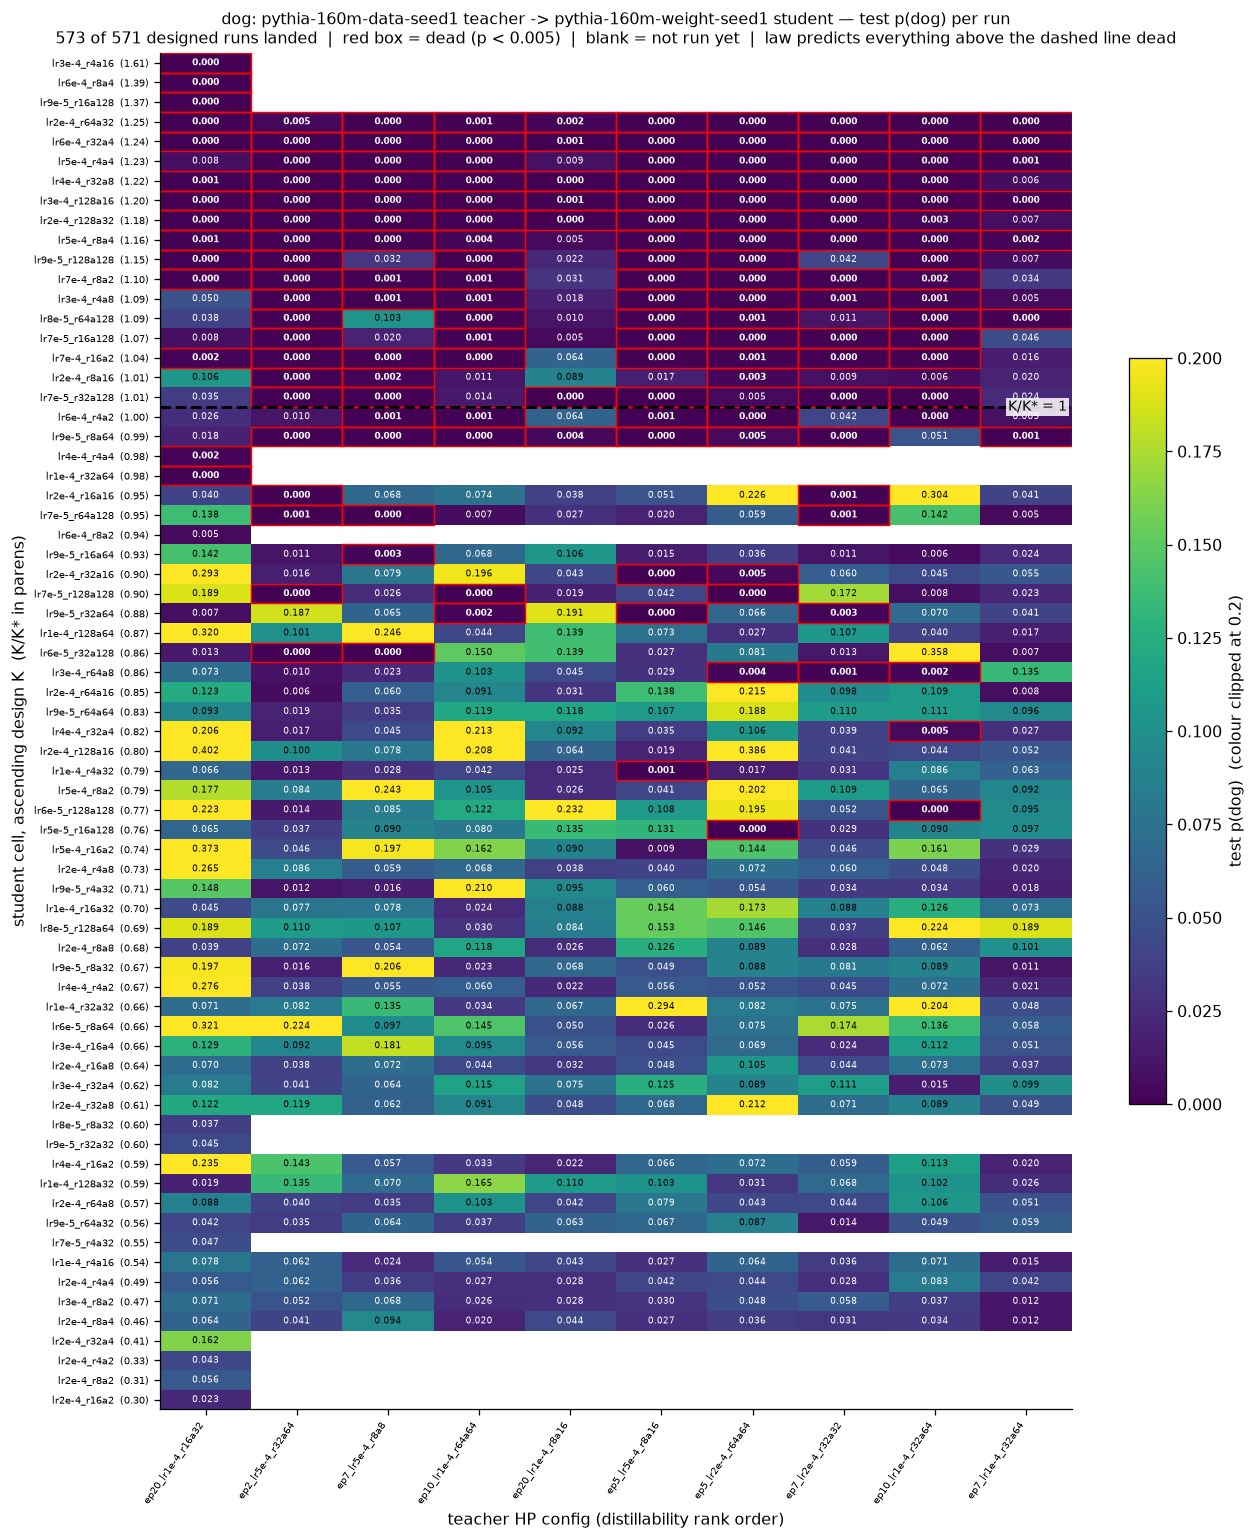

below K/K*=1: 420 runs, mean p 0.074, dead 9%
above K/K*=1: 153 runs, mean p 0.006, dead 77%


In [5]:
CELL_LABEL = {t: f"{t.removeprefix('ep20_')}  ({K_REL[t]:.2f})" for t in DESIGN_CELLS}
N_BELOW = sum(K_REL[t] < 1.0 for t in DESIGN_CELLS)     # y position of the K/K* = 1 rule


def cell_matrix(df: pd.DataFrame, ax, *, vmax=P_VMAX, cmap="viridis", fmt="{:.3f}", box=True,
                cbar_label="test p(dog)"):
    """Draw the (design cell x teacher) matrix of `df` on `ax`; return the image."""
    grid = (df.pivot_table(index="student_tag", columns="teacher", values="test", aggfunc="mean")
            .reindex(index=DESIGN_CELLS, columns=TEACHERS).rename(index=CELL_LABEL))
    im = aplots.annotated_heatmap(
        ax, grid, vmin=0.0, vmax=vmax, cmap=cmap, fmt=fmt, cell_fontsize=5.4, tick_fontsize=6.5,
        box_predicate=(lambda v: v < DEAD) if box else None, box_lw=0.9)
    ax.axhline(N_BELOW - 0.5, color="k", ls="--", lw=1.8)
    ax.annotate("K/K* = 1", xy=(0.995, N_BELOW - 0.5), xycoords=("axes fraction", "data"),
            fontsize=9, va="center", ha="right",
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.0))
    ax.set_xlabel("teacher HP config (distillability rank order)")
    ax.set_ylabel("student cell, ascending design K  (K/K* in parens)")
    return im


fig, ax = plt.subplots(figsize=(11.5, 13.5))
im = cell_matrix(runs, ax)
ax.set_title(f"{ANIMAL}: {TEACHER_BASE} teacher -> {STUDENT_BASE} student — test p(dog) per run\n"
             f"{len(runs)} of {len(jd)} designed runs landed  |  red box = dead (p < {DEAD})  |  "
             "blank = not run yet  |  law predicts everything above the dashed line dead",
             fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.55, label="test p(dog)  (colour clipped at 0.2)")
fig.tight_layout()
plt.show()

above, below = runs[runs.K_rel > 1], runs[runs.K_rel <= 1]
print(f"below K/K*=1: {len(below)} runs, mean p {below.test.mean():.3f}, dead {below.dead.mean():.0%}")
print(f"above K/K*=1: {len(above)} runs, mean p {above.test.mean():.3f}, dead {above.dead.mean():.0%}")

## 5. The same runs on the law's own frame — $K/K^\ast \times \alpha \times r$

The band-campaign layout: y = $K/K^\ast$ bin, x = LoRA $\alpha$, panel = LoRA rank, value = mean
test $p(\text{dog})$ over the runs in the square with the contributing count `n` beneath it. If
the law holds in this arm, every panel splits at the *same height* — the dashed $K/K^\ast = 1$
rule — no matter how $\alpha$ and $r$ were traded off to get there.

This design is sparse, so most squares are empty by construction (see §1) and single-run squares
are common; the counts are printed so a bright square backed by `n1` is not mistaken for a
surface.

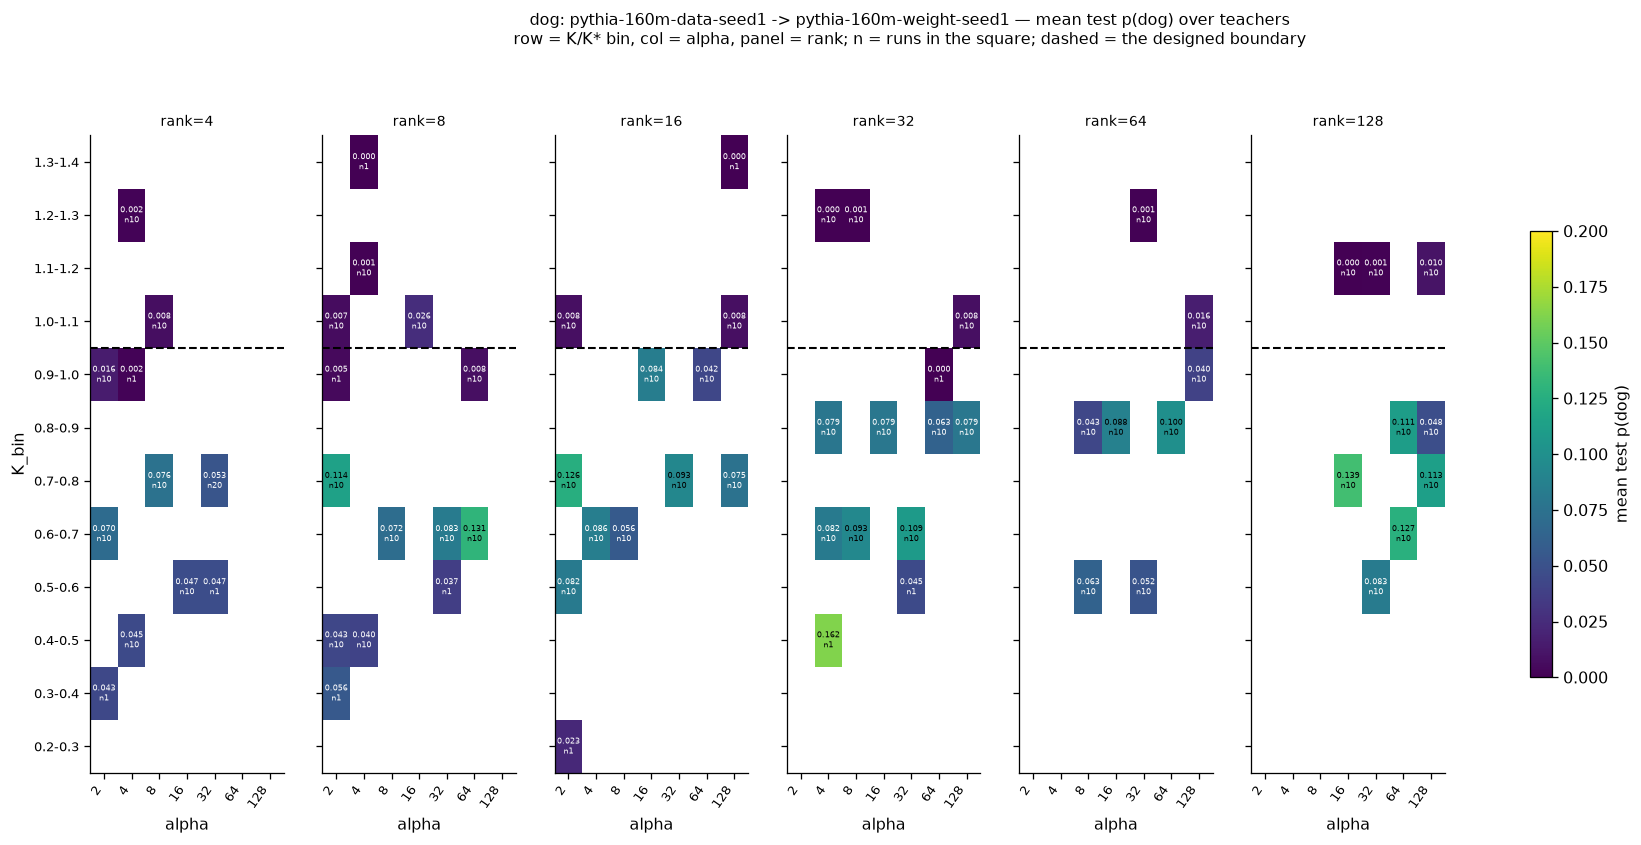

In [6]:
fig = aplots.facet_grid_heatmaps(
    runs, row="K_bin", col="alpha", val="test", col_facet="rank", agg="mean", orders=ORDERS,
    show_n=True, vmin=0.0, vmax=P_VMAX, fmt="{:.3f}", panel_w=3.0, row_h=0.40, cell_fontsize=5.2,
    title=(f"{ANIMAL}: {TEACHER_BASE} -> {STUDENT_BASE} — mean test p(dog) over teachers\n"
           "row = K/K* bin, col = alpha, panel = rank; n = runs in the square; "
           "dashed = the designed boundary"),
    cbar_label="mean test p(dog)")
for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
    if i % len(RANK_ORDER):          # y ticks once, not six times
        ax.set_yticklabels([])
    ax.axhline(BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.3)
plt.show()

## 6. Against the matched reference — is a `data-seed1` teacher worse than the original?

Same student base, same student cells, same teacher HP tags, same pool size and epochs: the only
thing that changes is which init the teacher was fine-tuned from. Squares are
$\Delta = p(\text{ds1 teacher}) - p(\text{original teacher})$, so **red = the `data-seed1` teacher
transfers more**, blue = the original does, near-white = they agree. A square needs both arms
present, so this panel is sparser than §4.

Colour is clipped at the 97th percentile of $|\Delta|$ (labels stay exact) — otherwise a couple of
large cells flatten everything else.

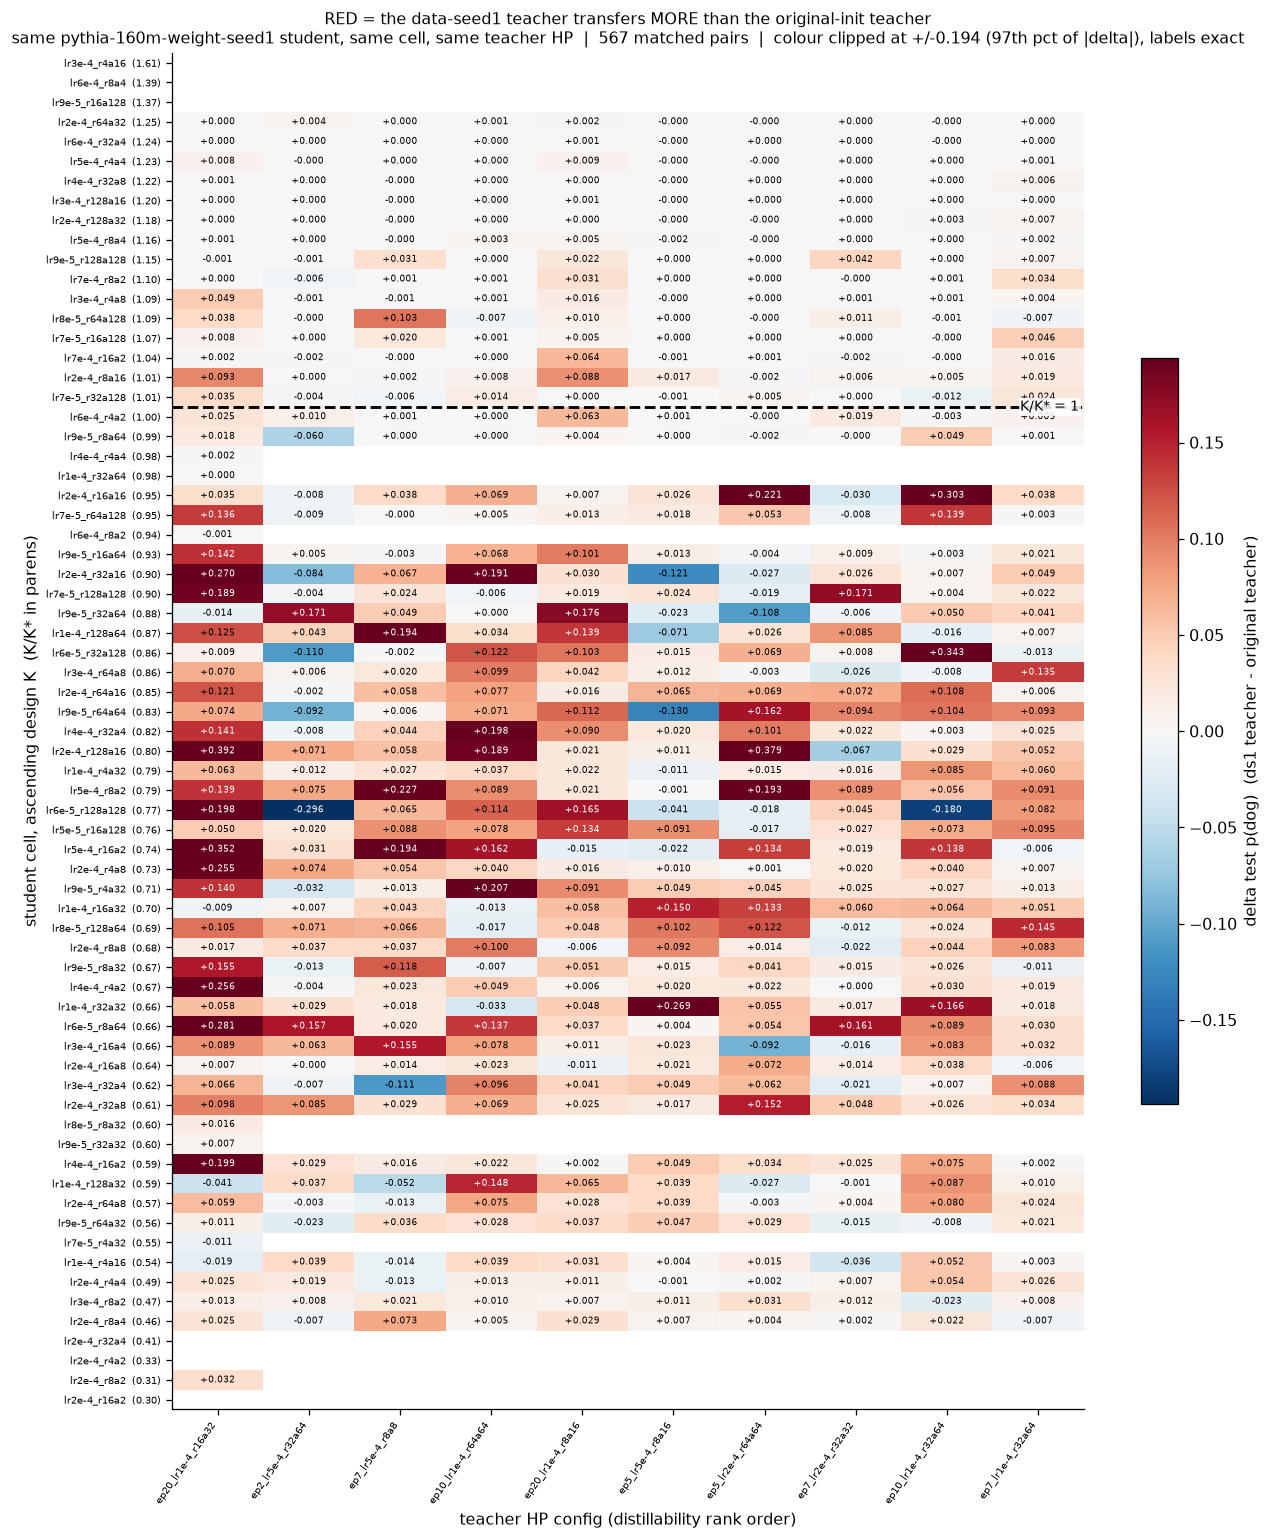

567 matched pairs over 63 shared cells x 10 teachers


In [7]:
def matrix_of(df: pd.DataFrame) -> pd.DataFrame:
    return (df.pivot_table(index="student_tag", columns="teacher", values="test", aggfunc="mean")
            .reindex(index=DESIGN_CELLS, columns=TEACHERS))


delta = matrix_of(runs) - matrix_of(ref)
d = delta.values[~np.isnan(delta.values)]
lim = float(np.nanpercentile(np.abs(d), 97))

fig, ax = plt.subplots(figsize=(11.5, 13.5))
im = aplots.annotated_heatmap(ax, delta.rename(index=CELL_LABEL), vmin=-lim, vmax=lim,
                              fmt="{:+.3f}", cell_fontsize=5.4, tick_fontsize=6.5, cmap="RdBu_r")
ax.axhline(N_BELOW - 0.5, color="k", ls="--", lw=1.8)
ax.annotate("K/K* = 1", xy=(0.995, N_BELOW - 0.5), xycoords=("axes fraction", "data"),
            fontsize=9, va="center", ha="right",
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.0))
ax.set_xlabel("teacher HP config (distillability rank order)")
ax.set_ylabel("student cell, ascending design K  (K/K* in parens)")
ax.set_title("RED = the data-seed1 teacher transfers MORE than the original-init teacher\n"
             f"same {STUDENT_BASE} student, same cell, same teacher HP  |  {len(d)} matched pairs  |  "
             f"colour clipped at +/-{lim:.3f} (97th pct of |delta|), labels exact", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.55, label="delta test p(dog)  (ds1 teacher - original teacher)")
fig.tight_layout()
plt.show()

paired = (runs.merge(ref, on=["teacher", "student_tag"], suffixes=("_ds1", "_ref"))
          .assign(K_rel=lambda f: f.student_tag.map(K_REL),
                  delta=lambda f: f.test_ds1 - f.test_ref))
print(f"{len(paired)} matched pairs over {paired.student_tag.nunique()} shared cells x "
      f"{paired.teacher.nunique()} teachers")

### 6b. Which teacher init is better, on the shared cells only

The §6 panel is a per-square picture; this is the summary the comparison actually rests on. The
population is the **matched pairs** — every (teacher HP, student cell) coordinate where *both*
arms have a run — so the two columns are drawn from an identical design and the difference cannot
come from one arm having been placed at easier cells.

Row unit: one matched pair, grouped by $K/K^\ast$ band. `wins` is the share of pairs where the
`data-seed1` teacher's student scores higher. Both arms are floored above the boundary, so the
`> 1.0` row is reported for completeness and carries no signal. A sign test on the pairs below
the boundary gives the $p$-value; it tests direction only, which is all a one-seed-per-cell
design supports.

In [8]:
from scipy import stats


def pair_block(name: str, sub: pd.DataFrame) -> dict:
    if sub.empty:
        return {"K/K* band": name, "pairs": 0}
    n_ds1, n_tot = int((sub.delta > 0).sum()), int((sub.delta != 0).sum())
    p = stats.binomtest(n_ds1, n_tot, 0.5).pvalue if n_tot else np.nan
    return {"K/K* band": name, "pairs": len(sub),
            "ds1 teacher mean": round(sub.test_ds1.mean(), 3),
            "original teacher mean": round(sub.test_ref.mean(), 3),
            "median delta": round(float(np.median(sub.delta)), 3),
            "ds1 wins": f"{(sub.delta > 0).mean():.0%}",
            "sign-test p": f"{p:.2g}"}


BANDS = [("0.3-0.6", 0.0, 0.6), ("0.6-0.8", 0.6, 0.8), ("0.8-1.0", 0.8, 1.0), ("> 1.0", 1.0, 9.9)]
shared_tab = pd.DataFrame(
    [pair_block("all shared", paired)]
    + [pair_block(f"below 1.0 -- {n}", paired[paired.K_rel.between(lo, hi, inclusive="right")])
       for n, lo, hi in BANDS[:3]]
    + [pair_block("above 1.0 (both dead)", paired[paired.K_rel > 1.0])]
    + [pair_block("all below 1.0", paired[paired.K_rel <= 1.0])]
).set_index("K/K* band")
display(shared_tab)

# The same contrast per teacher: does the ds1 advantage hold for every teacher HP, or is it
# carried by the one teacher with the most coverage?
per_teacher = (paired.groupby("teacher")
               .agg(pairs=("delta", "size"), ds1=("test_ds1", "mean"), original=("test_ref", "mean"),
                    median_delta=("delta", "median"), ds1_wins=("delta", lambda s: (s > 0).mean()))
               .reindex([t for t in TEACHERS if t in set(paired.teacher)]).round(3))
display(per_teacher)

,pairs,ds1 teacher mean,original teacher mean,median delta,ds1 wins,sign-test p
K/K* band,,,,,,
all shared,567,0.056,0.022,0.014,78%,1.8e-42
below 1.0 -- 0.3-0.6,84,0.056,0.036,0.014,77%,4.7e-07
below 1.0 -- 0.6-0.8,190,0.092,0.035,0.041,84%,1.2e-22
below 1.0 -- 0.8-1.0,143,0.061,0.020,0.019,76%,7.4e-10
above 1.0 (both dead),150,0.007,0.001,0.000,73%,2.6e-08
all below 1.0,417,0.074,0.030,0.025,80%,3.7e-36


,pairs,ds1,original,median_delta,ds1_wins
teacher,,,,,
ep20_lr1e-4_r16a32,63,0.096,0.023,0.035,0.889
ep2_lr5e-4_r32a64,56,0.040,0.034,0.000,0.571
ep7_lr5e-4_r8a8,56,0.057,0.024,0.020,0.732
ep10_lr1e-4_r64a64,56,0.060,0.012,0.023,0.893
ep20_lr1e-4_r8a16,56,0.054,0.015,0.022,0.946
ep5_lr5e-4_r8a16,56,0.046,0.029,0.008,0.661
ep5_lr2e-4_r64a64,56,0.066,0.030,0.003,0.679
ep7_lr2e-4_r32a32,56,0.040,0.024,0.005,0.732
ep10_lr1e-4_r32a64,56,0.064,0.023,0.025,0.786


## 7. The distribution — percentiles of transfer

Row unit: one evaluated run (teacher $\times$ cell, student seed 1). Percentiles are over runs,
not over teachers or cells, so they answer "if I draw a cell from this design, how good is it?"
and inherit the design's cell mix. The ECDF is the same data: the further right a curve sits, the
better the arm transfers.

,n,p50,p75,p90,p95,max,dead_frac
population,,,,,,,
ds1 teacher -- all design cells,573,0.038,0.081,0.139,0.197,0.402,0.272
ds1 teacher -- K/K* <= 1,420,0.056,0.098,0.172,0.212,0.402,0.090
ds1 teacher -- K/K* > 1,153,0.000,0.003,0.019,0.036,0.106,0.771
original teacher -- all landed at these cells,621,0.012,0.030,0.053,0.071,0.310,0.399
original teacher -- K/K* <= 1,471,0.020,0.038,0.060,0.093,0.310,0.223
SHARED cells -- ds1 teacher,567,0.038,0.081,0.139,0.197,0.402,0.270
SHARED cells -- original teacher,567,0.012,0.031,0.056,0.075,0.310,0.407
"SHARED, K/K* <= 1 -- ds1 teacher",417,0.056,0.098,0.172,0.212,0.402,0.091
"SHARED, K/K* <= 1 -- original teacher",417,0.020,0.040,0.063,0.102,0.310,0.211


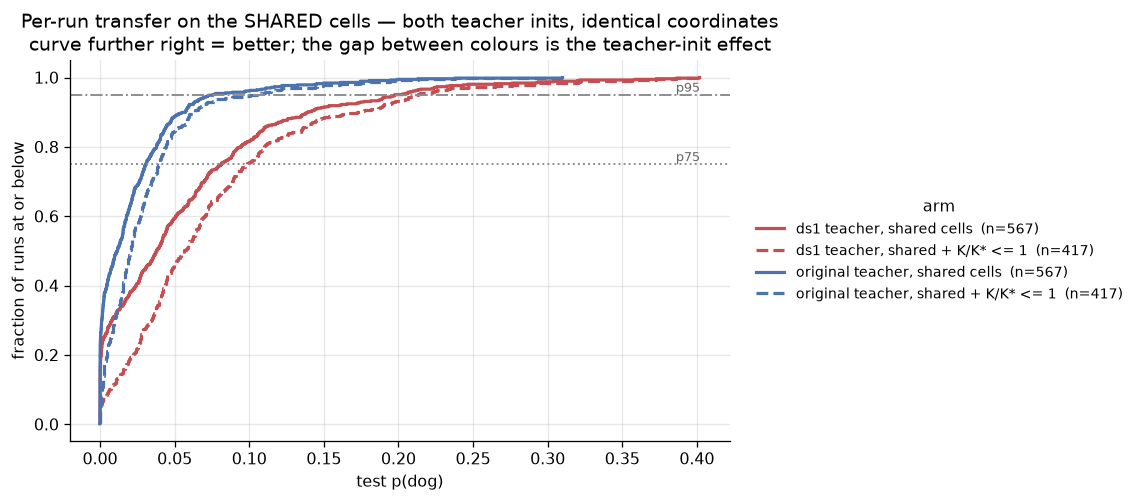

In [9]:
QS = [0.5, 0.75, 0.9, 0.95]


def pct_row(name: str, s: pd.Series) -> dict:
    return {"population": name, "n": len(s),
            **{f"p{int(q * 100)}": round(float(np.quantile(s, q)), 3) for q in QS},
            "max": round(float(s.max()), 3), "dead_frac": round(float((s < DEAD).mean()), 3)}


tab = pd.DataFrame([
    pct_row("ds1 teacher -- all design cells", runs.test),
    pct_row("ds1 teacher -- K/K* <= 1", runs[runs.K_rel <= 1].test),
    pct_row("ds1 teacher -- K/K* > 1", runs[runs.K_rel > 1].test),
    pct_row("original teacher -- all landed at these cells", ref.test),
    pct_row("original teacher -- K/K* <= 1", ref[ref.K_rel <= 1].test),
    # The like-for-like rows: identical coordinate set, so the two are directly comparable.
    pct_row("SHARED cells -- ds1 teacher", paired.test_ds1),
    pct_row("SHARED cells -- original teacher", paired.test_ref),
    pct_row("SHARED, K/K* <= 1 -- ds1 teacher", paired[paired.K_rel <= 1].test_ds1),
    pct_row("SHARED, K/K* <= 1 -- original teacher", paired[paired.K_rel <= 1].test_ref),
]).set_index("population")
display(tab)

fig, ax = plt.subplots(figsize=(7.4, 4.3))
for label, s, color, ls in [
        ("ds1 teacher, shared cells", paired.test_ds1, "#c44e52", "-"),
        ("ds1 teacher, shared + K/K* <= 1", paired[paired.K_rel <= 1].test_ds1, "#c44e52", "--"),
        ("original teacher, shared cells", paired.test_ref, "#4c72b0", "-"),
        ("original teacher, shared + K/K* <= 1", paired[paired.K_rel <= 1].test_ref, "#4c72b0", "--")]:
    aplots.ecdf_plot(ax, s, label=f"{label}  (n={len(s)})", color=color, ls=ls, lw=2.0)
for q, style in [(0.75, ":"), (0.95, "-.")]:
    ax.axhline(q, color="0.55", ls=style, lw=1.2)
    ax.text(0.402, q, f"p{int(q * 100)}", fontsize=8, color="0.4", va="bottom", ha="right")
ax.set(xlabel="test p(dog)", ylabel="fraction of runs at or below",
       title="Per-run transfer on the SHARED cells — both teacher inits, identical coordinates\n"
             "curve further right = better; the gap between colours is the teacher-init effect")
aplots.right_legend(ax, title="arm")
plt.show()

## 8. The core-65 arms — the same ds1 teachers into the *original* init and into `weight-seed2`

Two further arms (queued 2026-08-18, design read from each queue's own `jobs.jsonl`): the **same
10 ds1-finetuned teachers**, **65 shared student cells** ("core-65" = the 56-cell focus-20 ∪
band-48 dedup plus the 9-cell low-K strip — the current shared-design universe, distinct from
the 69-cell band above), student seed 1, distilled into the **original init**
(`dog-seed2seed-ds1-orig-core65`) and into **`weight-seed2`** (`-ws2-core65`).

Because core-65 lives on the band-48-era coordinates, the matched references are *designed*
coverage, not found scraps: `original -> data-seed1` and `original -> weight-seed2` exist
cell-for-cell from the band-48 campaigns, and 57/65 cells overlap the §2 band design for
`ds1 -> weight-seed1`. Three comparisons, all at matched (teacher HP, cell) coordinates:

- **8a. Direction** — `ds1 -> original` vs `original -> ds1`: between the same two inits, does
  distillation have a preferred direction?
- **8a. Receiving init** — `ds1 -> original` vs `ds1 -> weight-seed1`: same teachers, does the
  teacher's *ancestor* init receive its numbers better than an unrelated init?
- **8b. `ds1 -> weight-seed2`** vs `original -> weight-seed2` on the §5 law frame — a student
  equidistant from both teacher inits, so neither side holds a same-init advantage.

Partial-tolerant: coverage is printed first; the ws2 arm and parts of the low-K references may
still be draining.

In [10]:
CORE_QUEUES = {
    "ds1 -> orig": ROOT / "run_logs/queue_angela/dog-seed2seed-ds1-orig-core65",
    "ds1 -> ws2": ROOT / "run_logs/queue_angela/dog-seed2seed-ds1-ws2-core65",
}
_cells = {n: sorted({json.loads(ln)["key"].split("|")[3]
                     for ln in (q / "jobs.jsonl").read_text().splitlines()})
          for n, q in CORE_QUEUES.items()}
assert len(set(map(tuple, _cells.values()))) == 1, "core-65 arms disagree on cells"
CORE_CELLS = sorted(_cells["ds1 -> orig"], key=K_of)               # ascending design K
CORE_K = {t: K_of(t) / KSTAR for t in CORE_CELLS}
CORE_LABEL = {t: f"{t.removeprefix('ep20_')}  ({CORE_K[t]:.2f})" for t in CORE_CELLS}
N_BELOW_CORE = sum(CORE_K[t] < 1.0 for t in CORE_CELLS)

core_design = pd.DataFrame({"student_tag": CORE_CELLS})
for k in ("lr", "rank", "alpha"):
    core_design[k] = [parse_param_tag(t)[k] for t in CORE_CELLS]
core_design["K_rel"] = core_design.student_tag.map(CORE_K)
core_design["K_bin"] = k_bin(core_design.K_rel)
CORE_ORDERS = {"K_bin": [b for b in BIN_LABELS if b in set(core_design.K_bin)],
               "alpha": sorted(core_design.alpha.unique()),
               "rank": sorted(core_design["rank"].unique())}
CORE_BOUNDARY_ROW = next(i for i, b in enumerate(CORE_ORDERS["K_bin"])
                         if float(b.split("-")[0]) >= 1.0)


def load_core(numbers_base: str, student_base: str) -> pd.DataFrame:
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base=numbers_base,
                            dataset=DATASET,
                            lineages=[(t, t, student_base) for t in TEACHERS])
    r = r.rename(columns={"family": "teacher"})
    r = r[r.student_tag.isin(CORE_CELLS) & r.seed.eq(STUDENT_SEED)].copy()
    r["K_rel"] = r.student_tag.map(CORE_K)
    r["K_bin"] = k_bin(r.K_rel)
    r["dead"] = r.test.lt(DEAD).astype(int)
    return r


ARMS = {
    "ds1 -> orig": load_core(TEACHER_BASE, "pythia-160m"),
    "orig -> ds1": load_core(REF_BASE, "pythia-160m-data-seed1"),
    "ds1 -> ws1":  runs[runs.student_tag.isin(CORE_CELLS)].assign(
                       K_bin=lambda f: k_bin(f.K_rel)),   # the §2 band arm, on the 57 shared cells
    "orig -> ws1": load_core(REF_BASE, STUDENT_BASE),
    "ds1 -> ws2":  load_core(TEACHER_BASE, "pythia-160m-weight-seed2"),
    "orig -> ws2": load_core(REF_BASE, "pythia-160m-weight-seed2"),
}
cov = pd.DataFrame({n: {"runs": len(r), "cells": r.student_tag.nunique(),
                        "teachers": r.teacher.nunique(),
                        "mean p": round(r.test.mean(), 3),
                        "dead": f"{r.dead.mean():.0%}" if len(r) else "-"}
                    for n, r in ARMS.items()}).T
print(f"core-65: {len(CORE_CELLS)} cells, K/K* {min(CORE_K.values()):.2f}-"
      f"{max(CORE_K.values()):.2f}, {N_BELOW_CORE} below the boundary | "
      "coverage per arm (row unit: one arm; runs are teacher x cell, seed 1):")
display(cov)

core-65: 65 cells, K/K* 0.29-1.25, 50 below the boundary | coverage per arm (row unit: one arm; runs are teacher x cell, seed 1):


,runs,cells,teachers,mean p,dead
ds1 -> orig,650,65,10,0.117,7%
orig -> ds1,595,64,10,0.043,24%
ds1 -> ws1,561,57,10,0.057,27%
orig -> ws1,594,63,10,0.022,39%
ds1 -> ws2,205,65,4,0.029,10%
orig -> ws2,650,65,10,0.034,14%


### 8a. Direction and receiving init — the matrices

Left: the new arm. Middle: the same coordinates in the reverse direction. Right:
$\Delta$ = left $-$ middle, on the §6 colour rule (**red = the ds1 teacher / new arm wins**,
blue = the comparison wins). Rows are the 65 core cells in ascending design $K$; the dashed rule
is $K/K^\ast = 1$. Below: the same treatment for the receiving-init question on the 57 shared
cells, and a pooled $K/K^\ast$ profile of every arm on one axis (line = arm, mean over teachers
in the bin — the legend is the map).

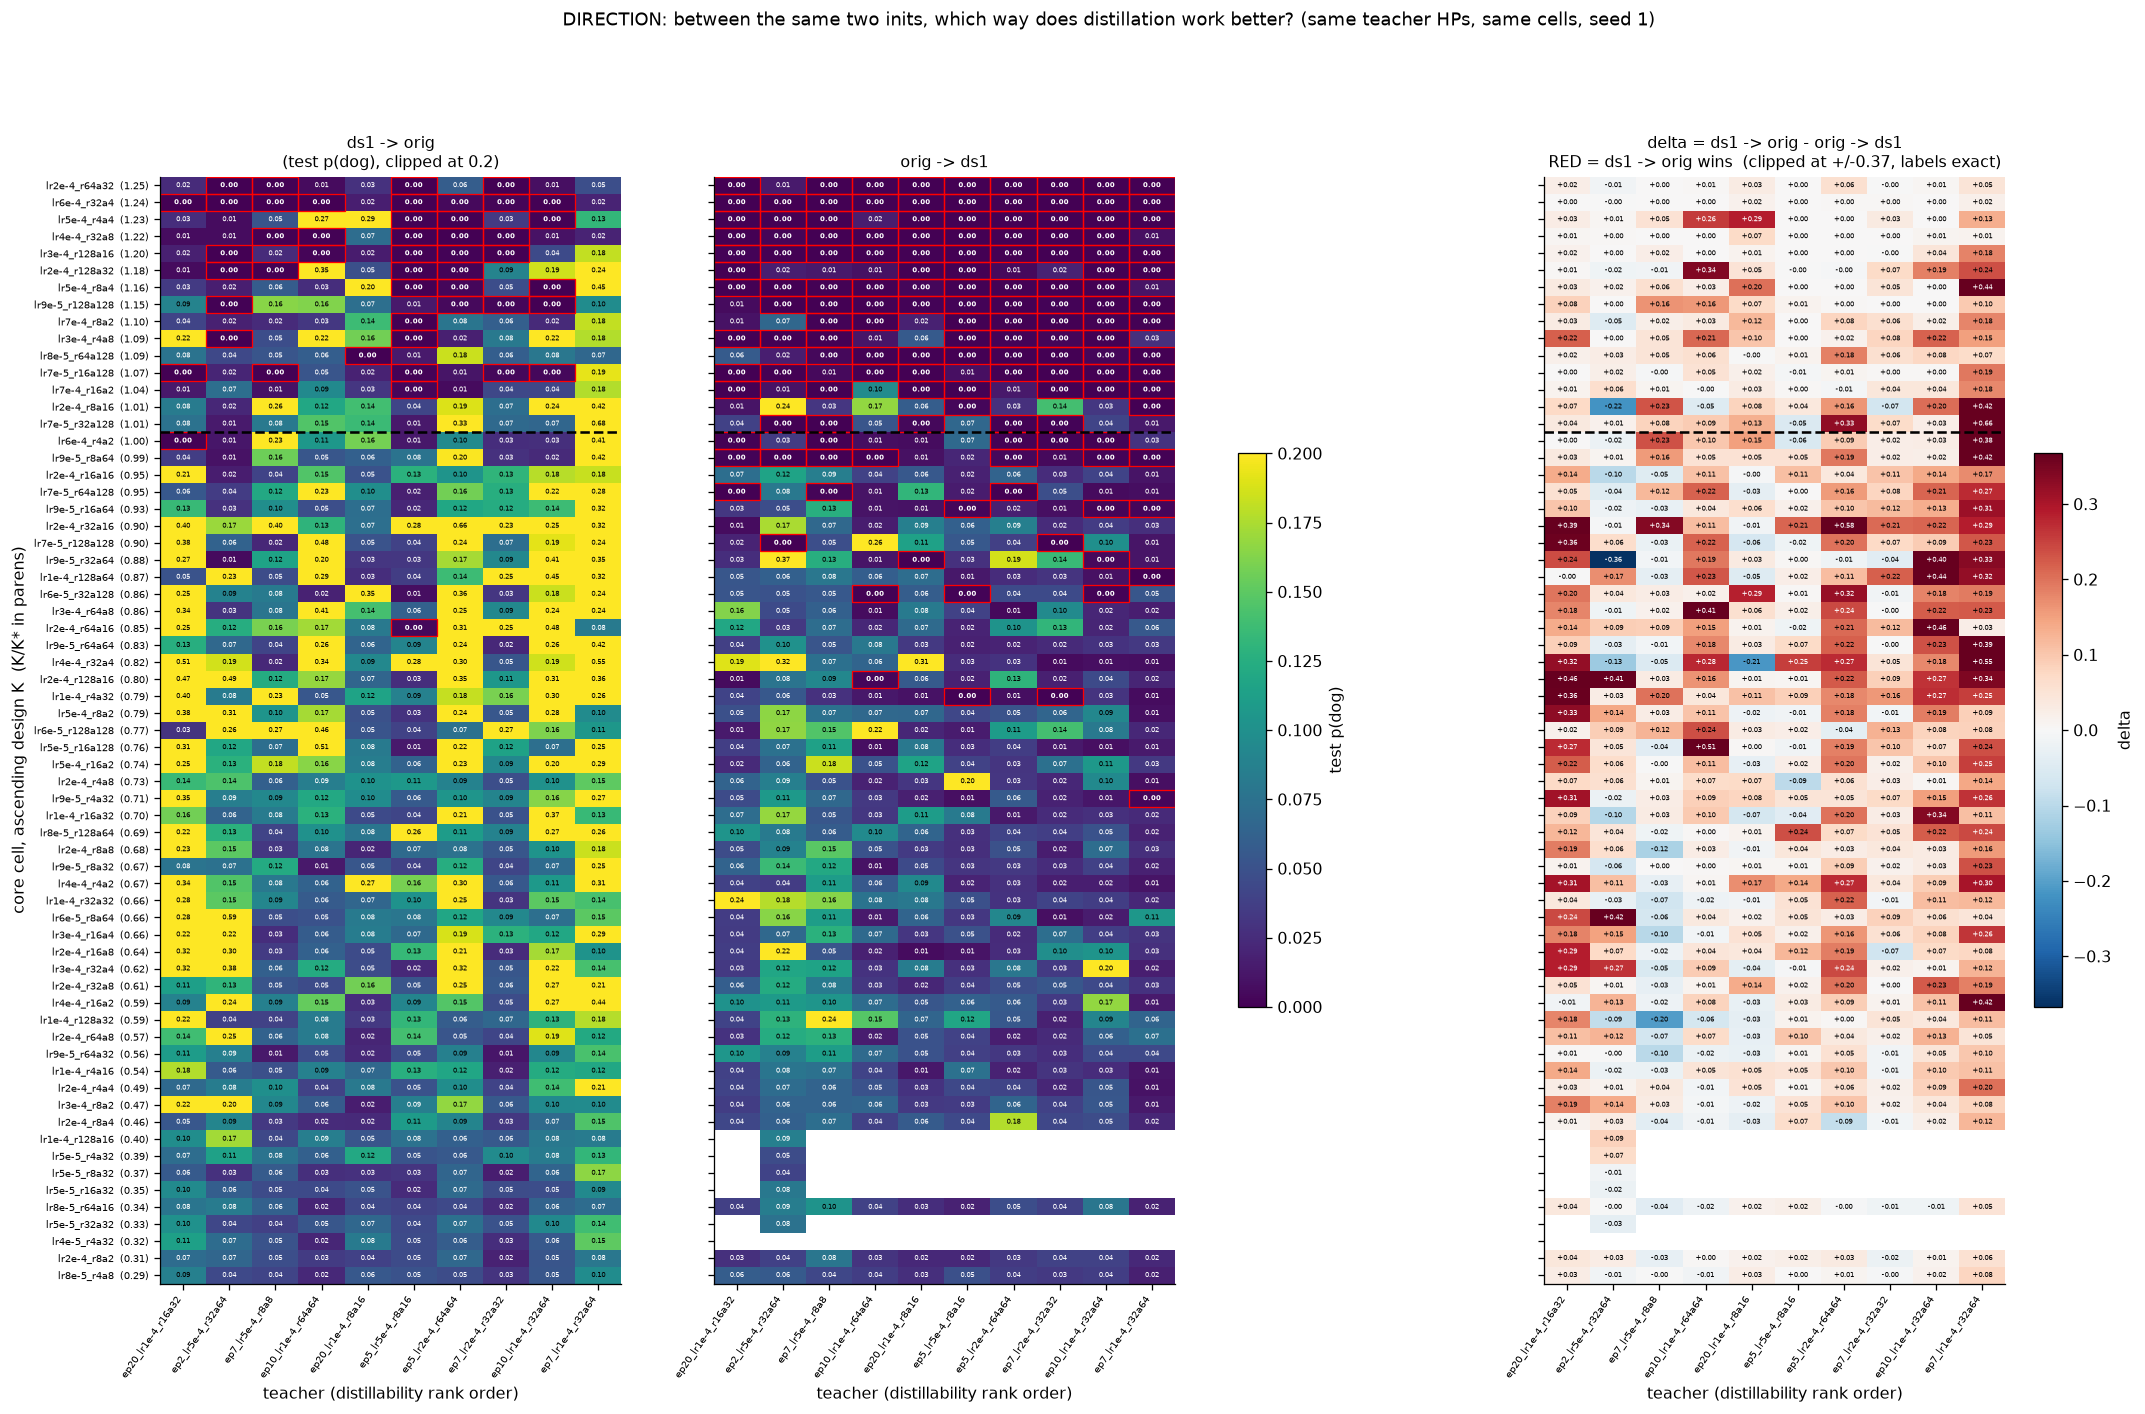

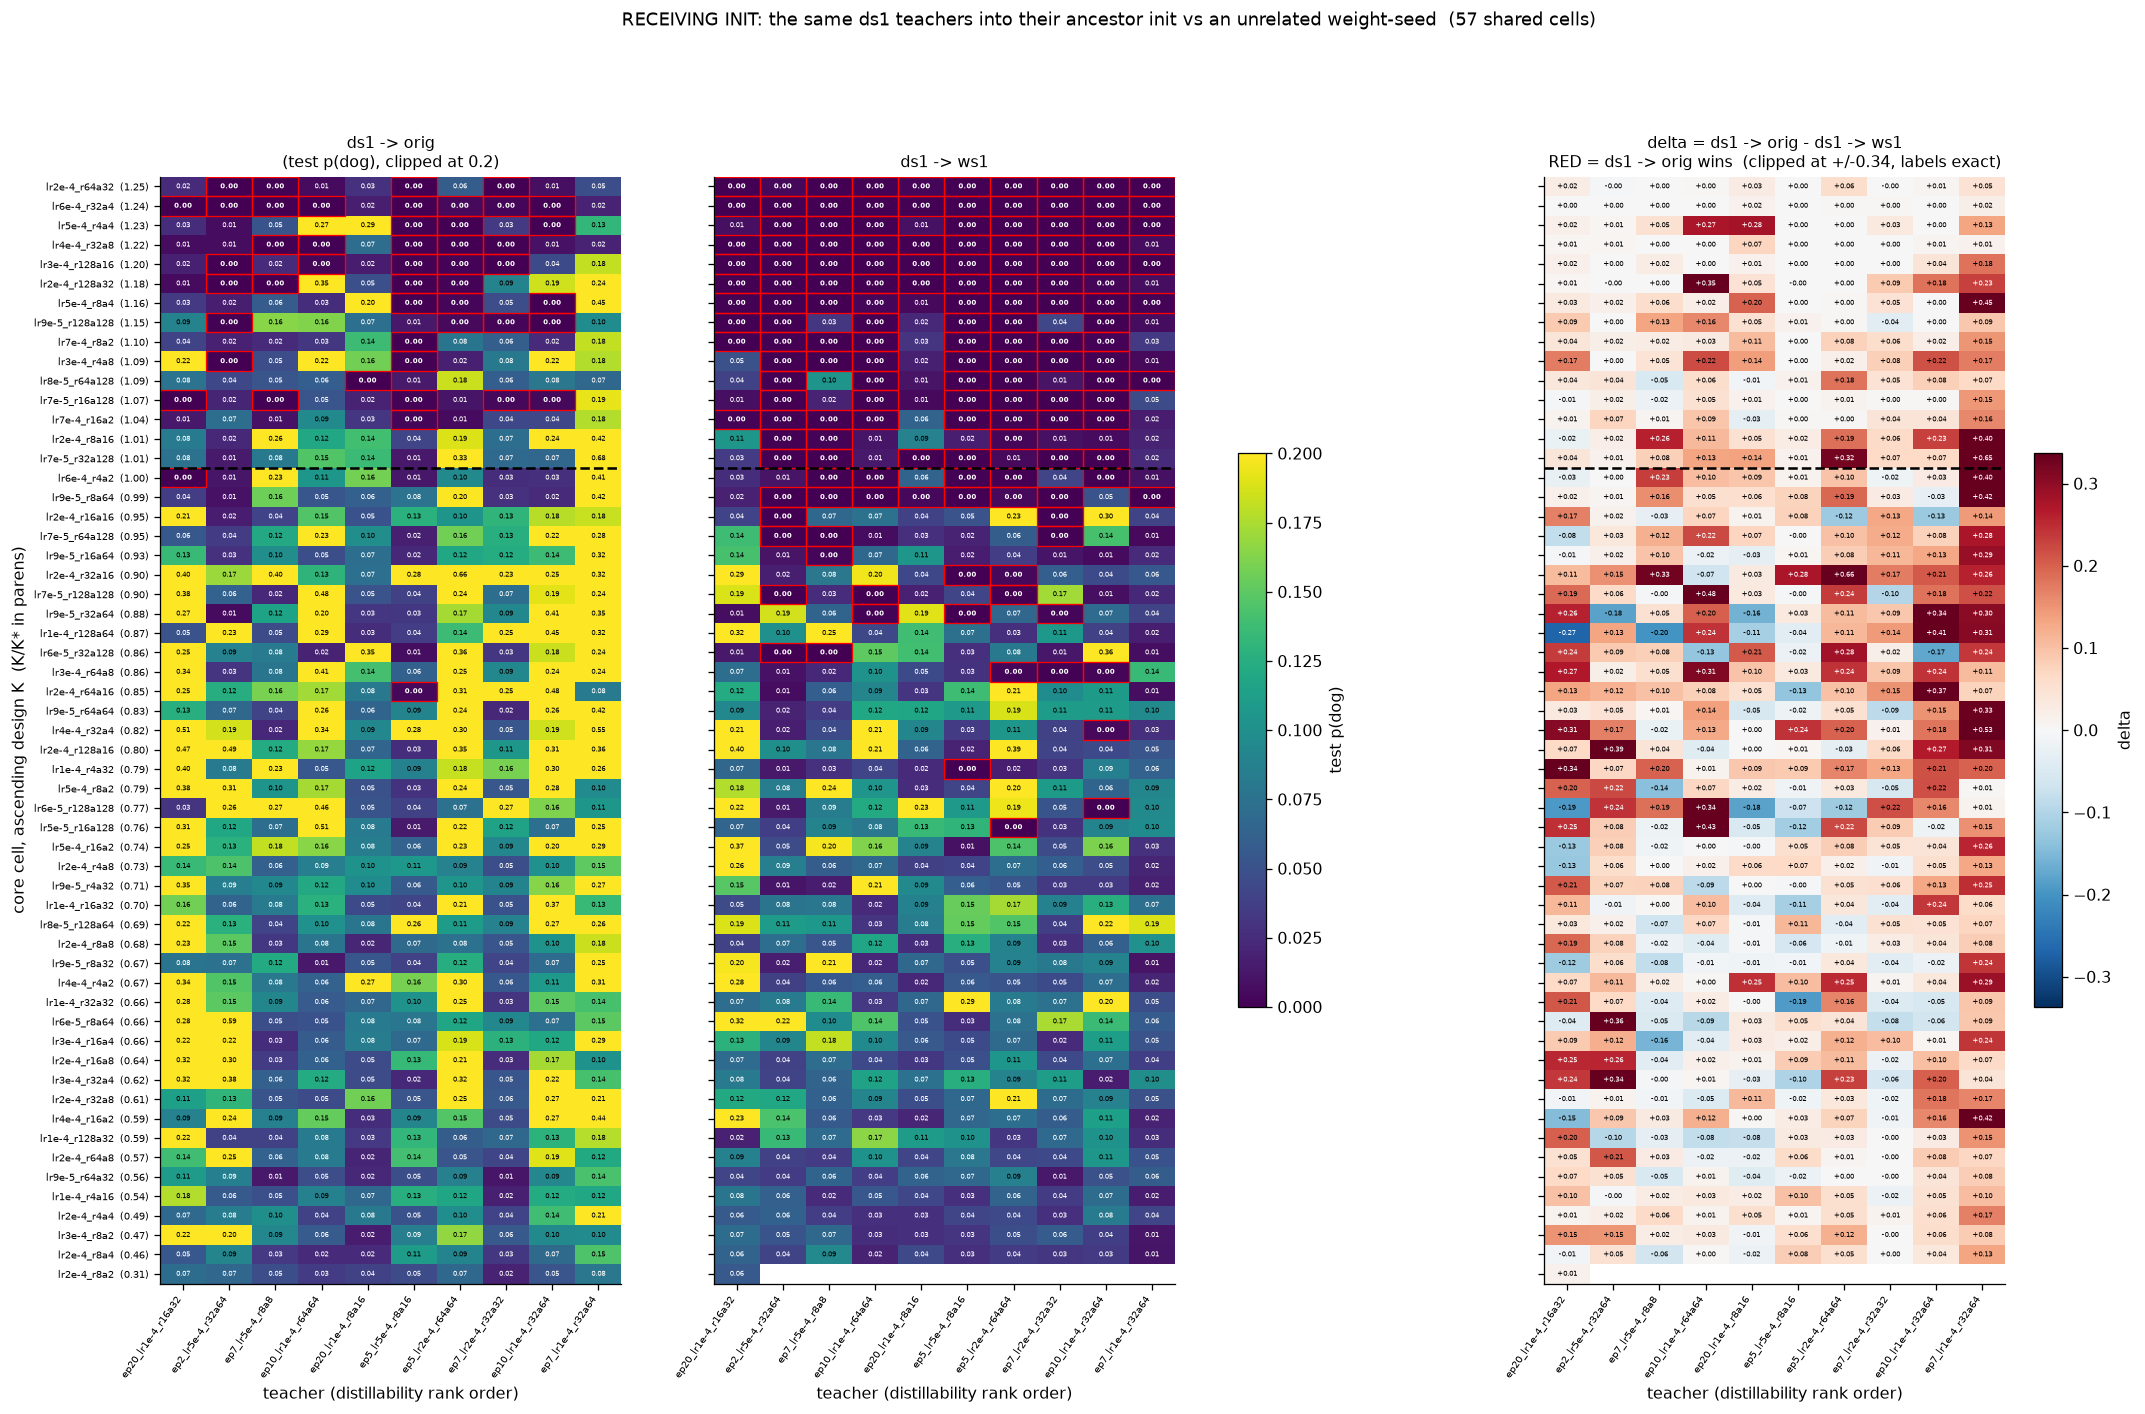

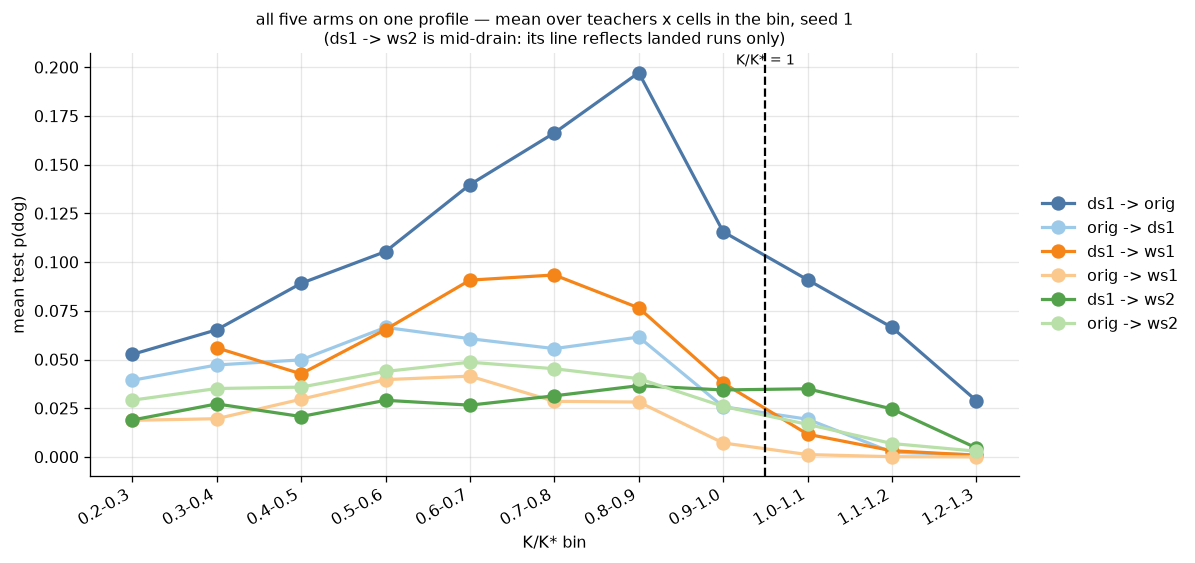

In [11]:
def core_matrix(df, ax, *, vmax=P_VMAX, cmap="viridis", fmt="{:.2f}", vmin=0.0, box=True,
                cells=None):
    cells = CORE_CELLS if cells is None else cells
    grid = (df.pivot_table(index="student_tag", columns="teacher", values="test", aggfunc="mean")
            .reindex(index=cells, columns=TEACHERS).rename(index=CORE_LABEL))
    im = aplots.annotated_heatmap(
        ax, grid, vmin=vmin, vmax=vmax, cmap=cmap, fmt=fmt, cell_fontsize=4.6, tick_fontsize=6.0,
        box_predicate=(lambda v: v < DEAD) if box else None, box_lw=0.8)
    n_below = sum(CORE_K[t] < 1.0 for t in cells)
    ax.axhline(n_below - 0.5, color="k", ls="--", lw=1.6)
    return im


def delta_frame(a: pd.DataFrame, b: pd.DataFrame, cells) -> pd.DataFrame:
    def m(df):
        return (df.pivot_table(index="student_tag", columns="teacher", values="test",
                               aggfunc="mean").reindex(index=cells, columns=TEACHERS))
    return m(a) - m(b)


def three_panel(name_a, name_b, cells, suptitle):
    a, b = ARMS[name_a], ARMS[name_b]
    delta = delta_frame(a, b, cells)
    lim = float(np.nanpercentile(np.abs(delta.values[~np.isnan(delta.values)]), 97)) or 0.01
    fig, axes = plt.subplots(1, 3, figsize=(22, 12.5), sharey=True)
    im0 = core_matrix(a[a.student_tag.isin(cells)], axes[0], cells=cells)
    axes[0].set_title(f"{name_a}\n(test p(dog), clipped at {P_VMAX})", fontsize=10)
    core_matrix(b[b.student_tag.isin(cells)], axes[1], cells=cells)
    axes[1].set_title(f"{name_b}", fontsize=10)
    im2 = aplots.annotated_heatmap(
        axes[2], delta.rename(index=CORE_LABEL), vmin=-lim, vmax=lim, cmap="RdBu_r",
        fmt="{:+.2f}", cell_fontsize=4.6, tick_fontsize=6.0)
    axes[2].axhline(sum(CORE_K[t] < 1.0 for t in cells) - 0.5, color="k", ls="--", lw=1.6)
    axes[2].set_title(f"delta = {name_a} - {name_b}\nRED = {name_a} wins  "
                      f"(clipped at +/-{lim:.2f}, labels exact)", fontsize=10)
    for ax in axes:
        ax.set_xlabel("teacher (distillability rank order)")
    axes[0].set_ylabel("core cell, ascending design K  (K/K* in parens)")
    fig.colorbar(im0, ax=axes[:2], shrink=0.5, label="test p(dog)")
    fig.colorbar(im2, ax=axes[2], shrink=0.5, label="delta")
    fig.suptitle(suptitle, fontsize=11, y=0.995)
    plt.show()


three_panel("ds1 -> orig", "orig -> ds1", CORE_CELLS,
            "DIRECTION: between the same two inits, which way does distillation work better? "
            "(same teacher HPs, same cells, seed 1)")

shared_ws1 = [t for t in CORE_CELLS if t in set(ARMS["ds1 -> ws1"].student_tag)]
three_panel("ds1 -> orig", "ds1 -> ws1", shared_ws1,
            "RECEIVING INIT: the same ds1 teachers into their ancestor init vs an unrelated "
            f"weight-seed  ({len(shared_ws1)} shared cells)")

# pooled K/K* profile, one line per arm
fig, ax = plt.subplots(figsize=(10.5, 5))
korder = CORE_ORDERS["K_bin"]
colors = {"ds1 -> orig": "#4c78a8", "orig -> ds1": "#9ecae9",
          "ds1 -> ws1": "#f58518", "orig -> ws1": "#fbc98d",
          "ds1 -> ws2": "#54a24b", "orig -> ws2": "#b8e0a8"}
for name, r in ARMS.items():
    prof = r.groupby("K_bin").test.mean().reindex(korder)
    ax.plot(range(len(korder)), prof.values, "o-", ms=8, lw=2, color=colors[name], label=name)
ax.axvline(CORE_BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.4)
ax.annotate("K/K* = 1", xy=(CORE_BOUNDARY_ROW - 0.5, ax.get_ylim()[1]), fontsize=9,
            ha="center", va="top")
ax.set_xticks(range(len(korder))); ax.set_xticklabels(korder, rotation=30, ha="right")
ax.set_xlabel("K/K* bin"); ax.set_ylabel("mean test p(dog)")
ax.set_title("all five arms on one profile — mean over teachers x cells in the bin, seed 1\n"
             "(ds1 -> ws2 is mid-drain: its line reflects landed runs only)", fontsize=10)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

### 8b. `ds1 -> weight-seed2` on the law frame — the §5 view, arm vs reference

Same layout as §5: row = $K/K^\ast$ bin, col = LoRA $\alpha$, panel = rank, value = mean test
$p(\text{dog})$ with the contributing count beneath. Three panels at identical coordinates: the new
`ds1 -> ws2` arm (mid-drain — blank squares are unfinished jobs), the `original -> ws2`
reference, and `ds1 -> ws1` (the §2 band arm on its 57 core-overlap cells) — the same teachers
into the *other* weight-seed, where the seed2seed advantage was found. If that advantage were
generic to weight-seed receivers, the first panel would out-run the second the way the third
does.

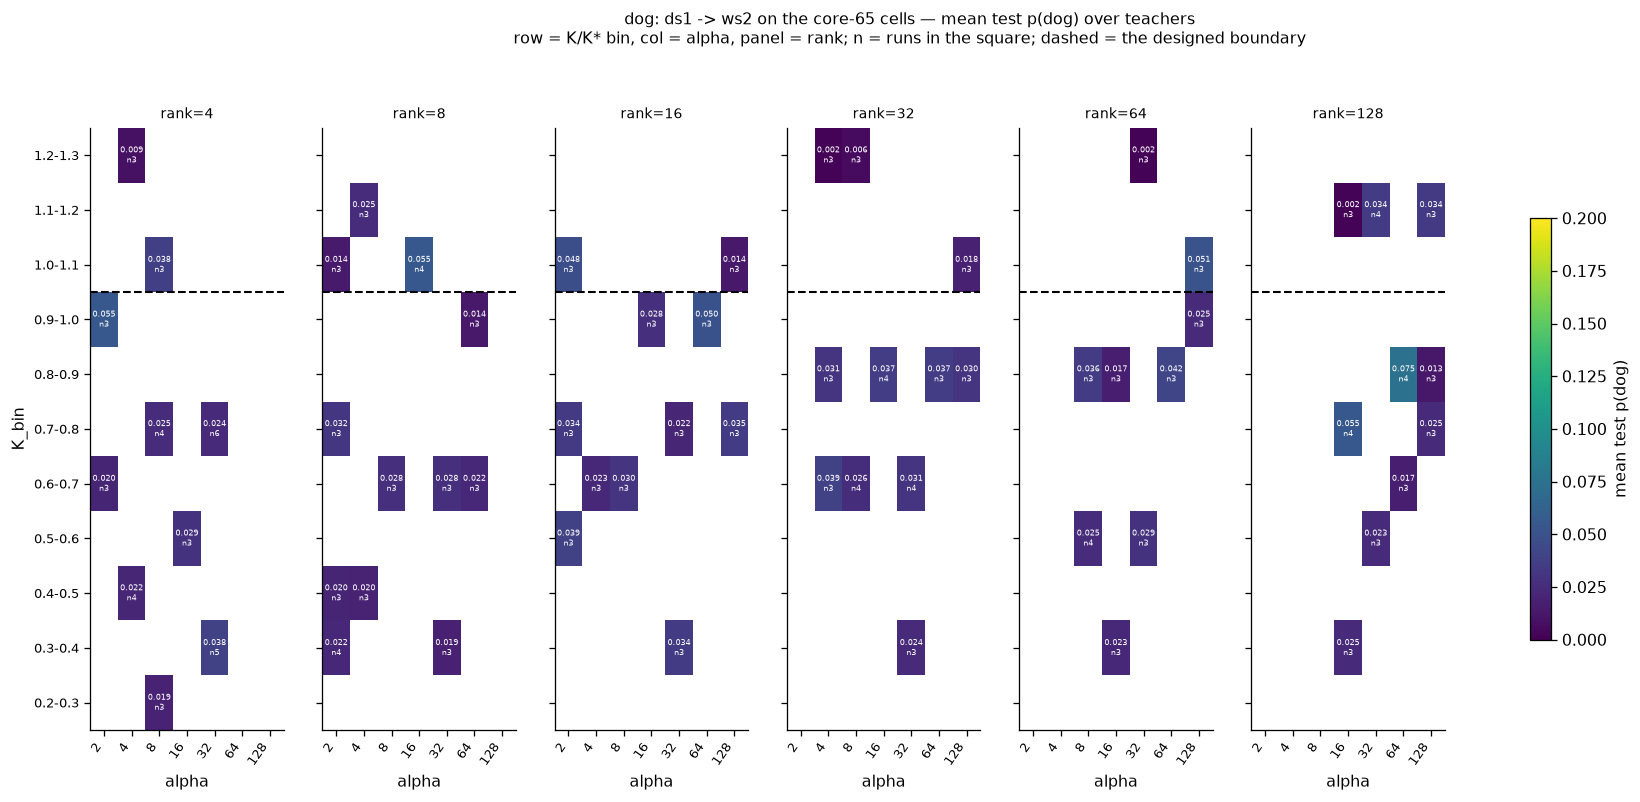

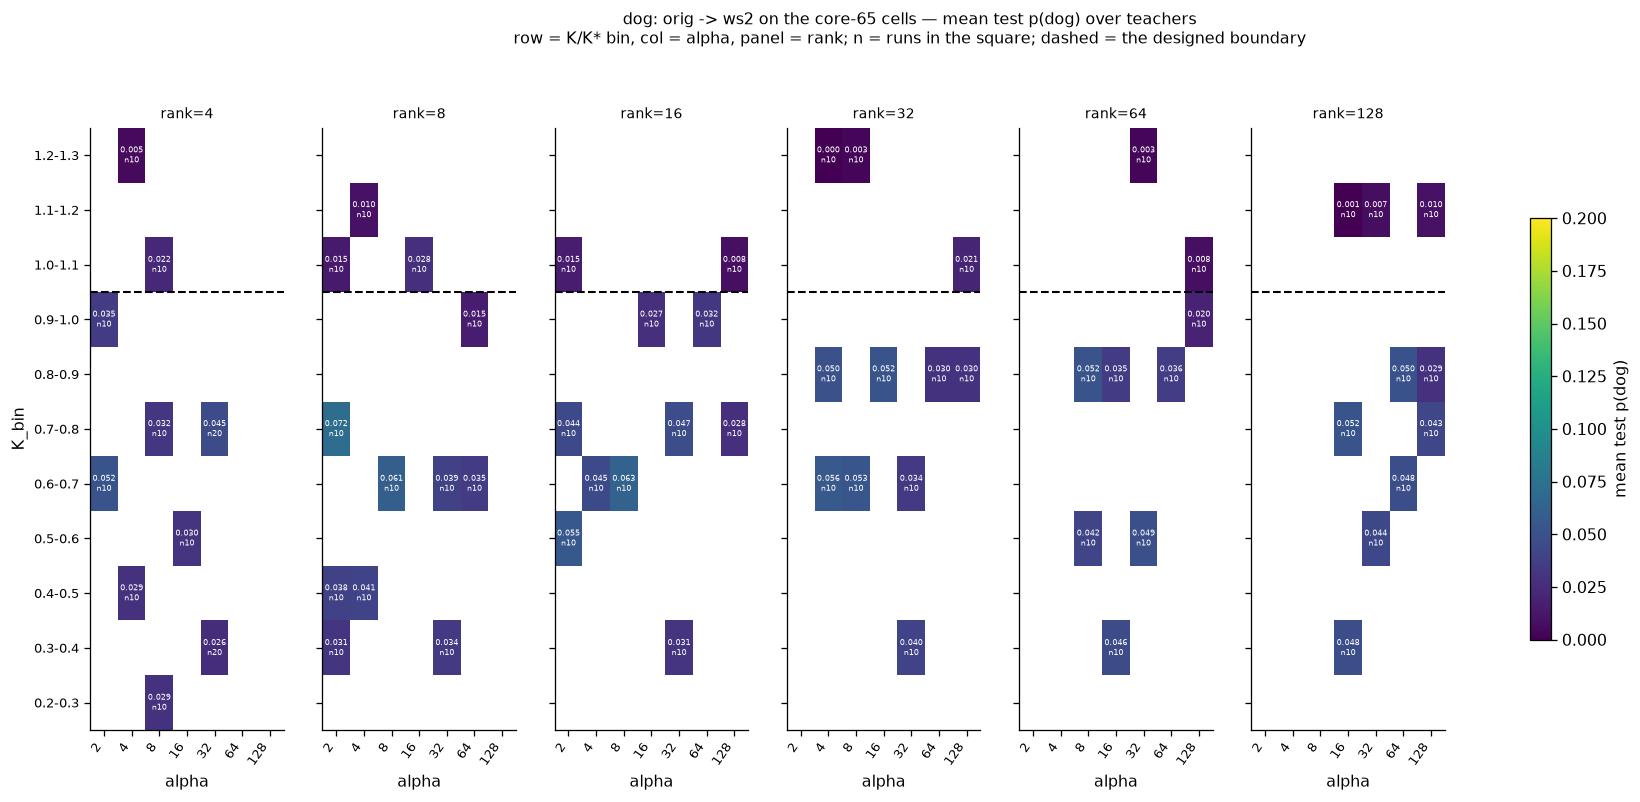

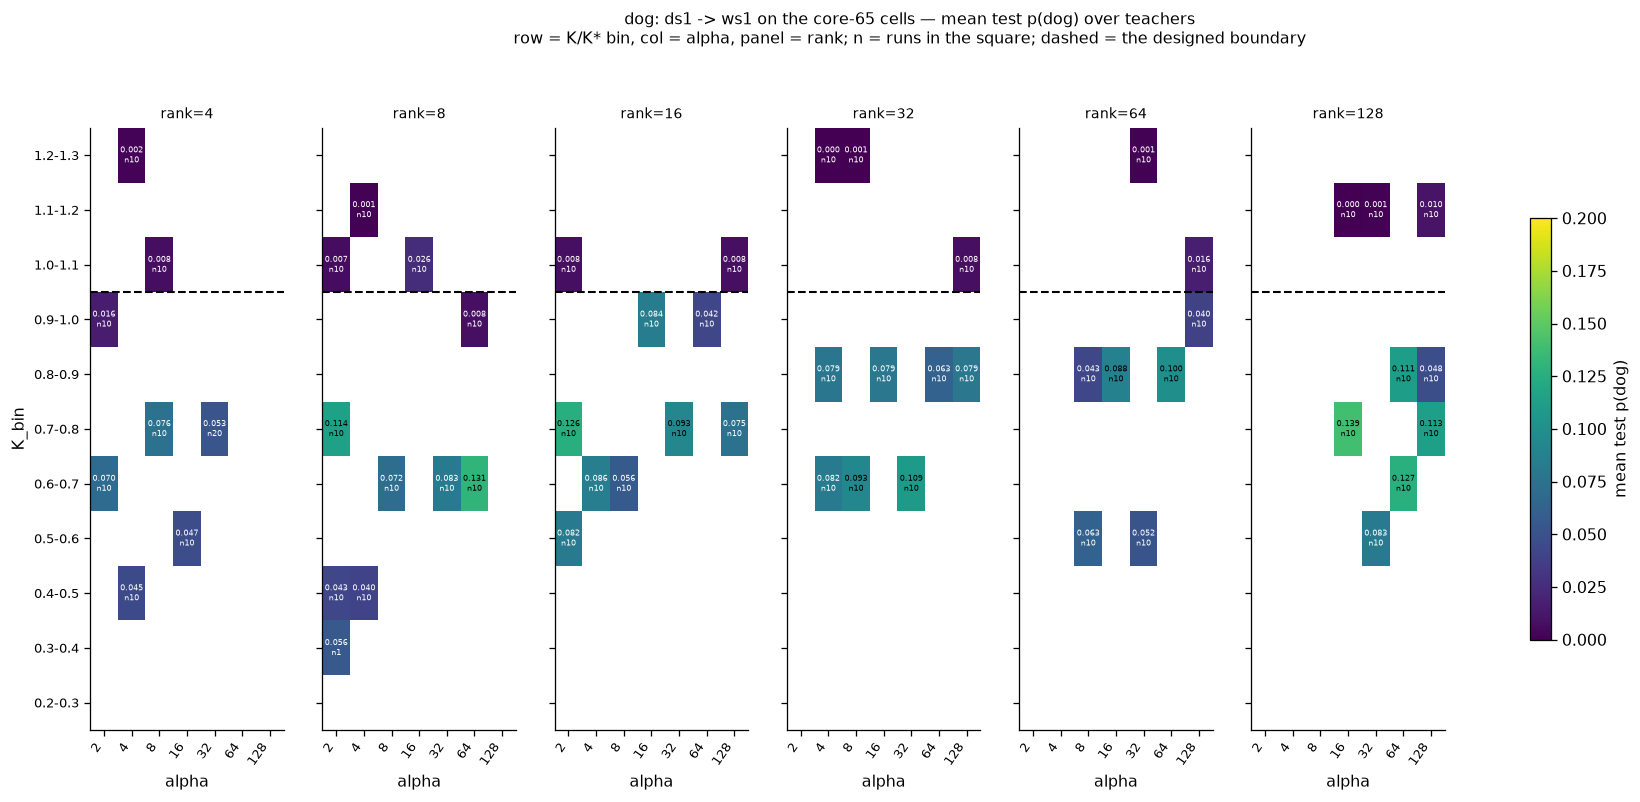

In [12]:
for name in ("ds1 -> ws2", "orig -> ws2", "ds1 -> ws1"):
    fig = aplots.facet_grid_heatmaps(
        ARMS[name], row="K_bin", col="alpha", val="test", col_facet="rank", agg="mean",
        orders=CORE_ORDERS, show_n=True, vmin=0.0, vmax=P_VMAX, fmt="{:.3f}",
        panel_w=3.0, row_h=0.40, cell_fontsize=5.2,
        title=(f"{ANIMAL}: {name} on the core-65 cells — mean test p(dog) over teachers\n"
               "row = K/K* bin, col = alpha, panel = rank; n = runs in the square; "
               "dashed = the designed boundary"),
        cbar_label="mean test p(dog)")
    for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
        if i % len(CORE_ORDERS["rank"]):
            ax.set_yticklabels([])
        ax.axhline(CORE_BOUNDARY_ROW - 0.5, color="k", ls="--", lw=1.3)
    plt.show()

### 8c. Matched-pair summaries — the numbers under the pictures

Row unit: one matched (teacher HP, cell) pair present in both arms, split at the boundary.
`A wins` = share of pairs where the first-named arm scores higher; the sign test is direction
only — all a one-seed design supports. The above-boundary row is floored on both sides.

In [13]:
def pair_summary(name_a: str, name_b: str) -> None:
    paired = (ARMS[name_a].merge(ARMS[name_b], on=["teacher", "student_tag"],
                                 suffixes=("_a", "_b"))
              .assign(K_rel=lambda f: f.student_tag.map(CORE_K),
                      delta=lambda f: f.test_a - f.test_b))
    print(f"=== {name_a}  vs  {name_b}: {len(paired)} pairs over "
          f"{paired.student_tag.nunique()} cells x {paired.teacher.nunique()} teachers ===")
    if paired.empty:
        print("no matched pairs yet"); return
    rows = []
    for band, sub in [("all", paired), ("below 1.0", paired[paired.K_rel <= 1.0]),
                      ("above 1.0 (floored)", paired[paired.K_rel > 1.0])]:
        if sub.empty:
            rows.append({"K/K* band": band, "pairs": 0}); continue
        n_a, n_tot = int((sub.delta > 0).sum()), int((sub.delta != 0).sum())
        pv = stats.binomtest(n_a, n_tot, 0.5).pvalue if n_tot else np.nan
        rows.append({"K/K* band": band, "pairs": len(sub),
                     f"mean {name_a}": round(sub.test_a.mean(), 3),
                     f"mean {name_b}": round(sub.test_b.mean(), 3),
                     "median delta": round(float(np.median(sub.delta)), 3),
                     "A wins": f"{(sub.delta > 0).mean():.0%}", "sign-test p": f"{pv:.2g}"})
    display(pd.DataFrame(rows).set_index("K/K* band"))


pair_summary("ds1 -> orig", "orig -> ds1")
pair_summary("ds1 -> orig", "ds1 -> ws1")
pair_summary("ds1 -> ws2", "orig -> ws2")
pair_summary("ds1 -> ws2", "ds1 -> ws1")
pair_summary("ds1 -> ws1", "orig -> ws1")   # the §6 comparison, restated on the core-65 coordinates

=== ds1 -> orig  vs  orig -> ds1: 595 pairs over 64 cells x 10 teachers ===


,pairs,mean ds1 -> orig,mean orig -> ds1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,595,0.122,0.043,0.042,80%,2.7e-50
below 1.0,445,0.140,0.055,0.051,77%,5.1e-31
above 1.0 (floored),150,0.068,0.010,0.020,88%,1.3e-22


=== ds1 -> orig  vs  ds1 -> ws1: 561 pairs over 57 cells x 10 teachers ===


,pairs,mean ds1 -> orig,mean ds1 -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,561,0.126,0.057,0.043,78%,2.1e-42
below 1.0,411,0.147,0.075,0.052,73%,9.4e-21
above 1.0 (floored),150,0.068,0.007,0.022,93%,2.3e-29


=== ds1 -> ws2  vs  orig -> ws2: 205 pairs over 65 cells x 4 teachers ===


,pairs,mean ds1 -> ws2,mean orig -> ws2,median delta,A wins,sign-test p
K/K* band,,,,,,
all,205,0.029,0.039,-0.008,41%,0.017
below 1.0,158,0.030,0.048,-0.014,31%,2e-06
above 1.0 (floored),47,0.024,0.010,0.008,77%,0.00035


=== ds1 -> ws2  vs  ds1 -> ws1: 179 pairs over 57 cells x 4 teachers ===


,pairs,mean ds1 -> ws2,mean ds1 -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,179,0.029,0.068,-0.019,42%,0.036
below 1.0,132,0.031,0.088,-0.038,25%,7.5e-09
above 1.0 (floored),47,0.024,0.009,0.009,89%,2.5e-08


=== ds1 -> ws1  vs  orig -> ws1: 561 pairs over 57 cells x 10 teachers ===


,pairs,mean ds1 -> ws1,mean orig -> ws1,median delta,A wins,sign-test p
K/K* band,,,,,,
all,561,0.057,0.022,0.014,78%,2.1e-42
below 1.0,411,0.075,0.030,0.026,80%,3.9e-36
above 1.0 (floored),150,0.007,0.001,0.000,73%,2.6e-08


## 9. Reading

1. **Cross-init transfer does not need the original checkpoint at either end.** A
   `data-seed1` teacher distils into a `weight-seed1` student well above its base rate
   ($p(\text{dog}) \approx 0.01$ for an untouched base), reaching $\approx 0.4$ at the best cell.
   The effect is generic to two independently-initialised models, not a property of
   `pythia-160m` being one of them.

2. **The collapse boundary transfers to this arm at the pooled anchor.** §4 and §5 split at the
   dashed rule without a per-arm refit: nearly everything above $K/K^\ast = 1$ is dead, the live
   band sits below it. This is the cheapest possible confirmation that $K^\ast$ is not
   arm-specific in the way `DEAD_SEED` thresholds are.

3. **The response below the boundary is humped, not monotone** — §3's profiles and the §7
   conditional percentiles peak around $K/K^\ast \approx 0.6$–$0.8$ and fall off again toward the
   rule, matching the conditional-transfer refit rather than "closer to the cliff is better".

4. **On the shared cells the `data-seed1` teacher beats the original-init teacher** into the same
   `weight-seed1` students (§6b), and the advantage lives entirely *below* the boundary — above it
   both arms are floored, so the $\Delta$ panel goes white there. Both teacher families are
   saturated on the held-out preference set ($p = 1.000$), so this is not a teacher-strength
   difference. The natural reading is that what a teacher's numbers carry is *not* graded by how
   close the student's init is to the teacher's — the original checkpoint has no privileged status
   as a source.

**Caveats.**

- Partial coverage: the campaign is still draining and three teachers carry most of the landed
  runs, so the pooled means in §5 and §7 are weighted toward those teachers. §2 prints the split.
- One student seed per cell. Near the boundary the seed variance is large (the K-rung work
  measured 0.22–0.43 across seeds at mid-ramp cells), so individual bright squares in §4 are not
  reliable rankings of cells.
- The §6 reference is *found*, not designed: it is whatever the earlier original-init campaigns
  happen to have run at these coordinates, and those campaigns placed their cells for a different
  band. The matched-pair comparison is honest per pair, but the pair *set* is an intersection, not
  a control arm.